In [270]:
%load_ext autoreload
%autoreload 2

import requests, json, time
import os
import numpy as np
import matplotlib.pyplot as plt
import random as rnd
from tqdm.notebook import tqdm
import re
import pandas as pd
import matplotlib.pyplot as plt
from lxml import etree as et
from collections import Counter
import birth_death_utils as bd
import artificial_collations as ac
import output_utils as u
import pickle
import warnings
import networkx as nx
import subprocess
import dendropy
from Espalier import MAF


warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Generate simulated traditions

In [ ]:
### parameter values

lda = 3.2*10**(-2)
mu = 1.4*10**(-2)
Tact = 250
Tinact = 250
n_witnesses = 8
n_verses = 1000
p_new_locus = 0.004
p_mod = 0.05
p_inov = 0.2
n_sims = 100

simulations_path = 'simulations_data/simulated_traditions_24_07'
if not os.path.isdir(simulations_path):
    os.mkdir(simulations_path)

with open(f'{simulations_path}/parameters.json', 'w') as f:
    json.dump(
        {'lambda':lda,
        'mu':mu,
        'Tact':Tact,
        'Tinact':Tinact,
        'witnesses_number':n_witnesses,
        'verse_numbers':n_verses,
        'p_new_locus':p_new_locus,
        'p_mod':p_mod,
        'p_inov':p_inov,
        'simulation_numbers':n_sims},
        f
    )

In [ ]:
### Simulations

for k in tqdm(range(n_sims)):
    g = bd.generate_tree_fixed_size(lda, mu, Tact, Tinact, n_witnesses)
    inv,seqs = ac.generate_collation_from_tree(g, n_verses, p_new_locus, p_mod, p_inov)
    loc_sizes,seqs = ac.reduce_collation(inv,seqs)
    max_val = max([max(l.values()) for l in loc_sizes.values() if l != {}])

    st  = bd.generate_stemma(g, assign_length=True)

    nexus_sequence = u.trad_to_nexus(st, seqs, loc_sizes, f'seq_{k}')
    newick_graph = u.to_newick(st, root=bd.root(st), node_attrs=['state', 'birth_time'], edge_attrs=['length'])

    with open(f'{simulations_path}/sequences_{k}.nex', 'w') as f:
        f.write(nexus_sequence)
    
    with open(f'{simulations_path}/tree_{k}.newick', 'w') as f:
        f.write(newick_graph)
    
    with open(f'{simulations_path}/sequences_{k}.pickle', 'wb') as f:
        pickle.dump(seqs,f)
    
    for n in st.nodes():
        st.nodes[n]['seq']= None
    
    with open(f'{simulations_path}/tree_{k}.pickle', 'wb') as f:
        pickle.dump(st, f)

  0%|          | 0/100 [00:00<?, ?it/s]

# Run MCMC inferences from BEAST2

In [ ]:
output_dir = os.getcwd()+'/beast_output/'
if not os.path.isdir(output_dir):
    os.mkdir(output_dir)

beast_path = 'BEAST2'

In [ ]:
### generate beast xml config files and run inferences

for k in tqdm(range(n_sims)):
    with open(f'{simulations_path}/tree_{k}.pickle', 'rb') as f:
        st = pickle.load(f)
    with open(f'{simulations_path}/sequences_{k}.pickle', 'rb') as f:
        wits_seqs = pickle.load(f)
    dates = {n:st.nodes[n]['birth_time'] for n in st.nodes() if st.nodes[n]['state']}

    model = u.BeastModel(seqs=wits_seqs,dates=dates,seq_name=f'sequence_{k}', model='fbd',n_iter=4*10**6)
    model.generate_xml().write(f'{simulations_path}/fdb_beast_{k}.xml')

    subprocess.run([f"{beast_path}/beast/bin/beast",
        "-overwrite", f"-prefix {output_dir}",
        f"{simulations_path}/fdb_beast_{k}.xml"])

In [ ]:
### generate consensus trees

for k in tqdm(range(n_sims)):
    subprocess.run([f'{beast_path}/beast/bin/treeannotator',
     '-height median', f'-file {output_dir}fdb_beast_{k}-sequence_{k}.trees consensus_{k}.nex' ])    

In [3]:
### load ground-truth stemmata and infered consensus trees

simulations_path = 'simulations_data/simulated_traditions_24_07'
n_sims = 100

st_inf = []
st_gt = []
for k in tqdm(range(n_sims)):
    tree = dendropy.Tree.get(path=f"beast_output/consensus_{k}.nex", schema="nexus", extract_comment_metadata=True)
    st_inf.append(u.dendropy_to_networkx(tree))
    with open(f"simulations_data/simulated_traditions_24_07/tree_{k}.pickle", "rb") as f:
        st_gt.append(pickle.load(f))
        # bd.draw_tree(st_inf, f'draft/stemmata_drawings/st_inf_{k}')

  0%|          | 0/100 [00:00<?, ?it/s]

## Branch length correlations

In [272]:
length_list_gt = []
length_list_inf = []

for k in tqdm(range(n_sims)):
    taxa = dendropy.TaxonNamespace()
    g = st_gt[k]
    for n in g.nodes():
        if g.nodes[n]['state']:
            g.nodes[n]['label'] = f'ms_{n}'

    with open('draft/test_gt.nex','w') as f:
        f.write('#NEXUS\n')
        f.write('Begin trees;\n')   
        newick_string = u.to_newick(g, bd.root(g),node_attrs=['state'], edge_attrs=['length'])
        f.write(f"tree TREE_MCC_median = {newick_string};\n")
        f.write("End;")

    testgt = dendropy.Tree.get(path=f"draft/test_gt.nex", schema="nexus", extract_comment_metadata=True, rooting="default-rooted", taxon_namespace=taxa)
    testinf = dendropy.Tree.get(path=f"beast_output/consensus_{k}.nex", schema="nexus", extract_comment_metadata=True,rooting="default-rooted",taxon_namespace=taxa)

    try:
        maf = MAF.get_maf(testinf,testgt)
    except Exception as e:
        continue

    for t in maf:
        if len(list(t.leaf_node_iter())) >= 2:
            for leaf in t.leaf_node_iter():
                label = leaf.taxon.label
                gt_leaf = testgt.find_node_with_taxon_label(label)
                inf_leaf = testinf.find_node_with_taxon_label(label)
                if inf_leaf._annotations['length_median'].value != '':
                    gt_length = int(re.findall(r"length=([0-9]*)",gt_leaf.comments[0])[0])
                    inf_length = float(inf_leaf._annotations['length_median'].value)
                    length_list_gt.append(gt_length)
                    length_list_inf.append(inf_length)

  0%|          | 0/100 [00:00<?, ?it/s]

In [273]:
plot_data = [[] for k in range(9)]
for gt,inf in zip(height_list_gt,height_list_inf):
    if gt <= 8:
        plot_data[gt].append(inf)

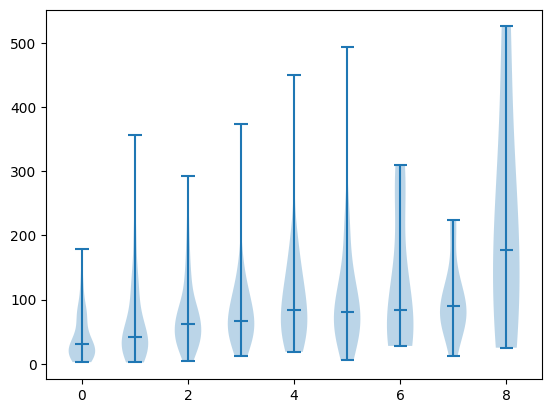

In [274]:
plt.violinplot(plot_data, positions= list(range(9)),showmedians=True,showextrema=True);